# 04. Flood labels and the final county-month table

**Goal:** build the flood labels from four sources, create the target (will there be a flood **next month**?), add the county flood history, join everything from notebooks 01-03, and check that the result is identical to the pipeline's table.

| source | what it is | raw file | how we get the flag |
|---|---|---|---|
| DesInventar | national disaster records, county x month | `data/raw/flood_labels/desinventar/DI_Crosstab_floods_county_yearmonth.xls` | built here from the raw file |
| Global Flood Database (GFD) | satellite flood area per event and county | `data/raw/flood_labels/global_flood_database/kenya_gfd_county_floods.csv` | built here from the raw file |
| DFO | Dartmouth Flood Observatory events with free-text places | `.dbf` list + `data/reference/place_to_county.csv` | read from the pipeline's `labels_sources.csv` |
| EM-DAT | large international flood events | `.xlsx` (licensed, never in git) + private place lookup | read from the pipeline's `labels_sources.csv` |

**Inputs:** `data/interim/nb_grid.csv`, `nb_rain_ndvi_climate.csv`, `nb_soil_rivers.csv`, `nb_static_county.csv` (notebooks 01-03) and the raw label files above.

**Outputs:** `data/interim/nb_flood_labels.csv` (labels only) and `data/interim/nb_model_table_full.csv` (the final table, 14,664 rows x 70 columns). Both are in `data/interim/`, which is git-ignored, because they contain EM-DAT-derived columns.

**Licence rule:** EM-DAT rows and events are never printed in this notebook. We only show counts and rates.

The reference is `src/data/09_labels.py`, `10_labels_combined.py`, `11_history.py` and `build_model_table.py`.

In [1]:
# import the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

In [2]:
# load the grid and the crosswalk (county names and codes)
grid = pd.read_csv("../../data/interim/nb_grid.csv", dtype={"pcode": str})
cw = pd.read_csv("../../data/reference/kenya_county_crosswalk.csv", dtype=str)
cw["desinventar_code"] = cw["desinventar_code"].str.zfill(2)
print(grid.shape, cw.shape)
cw.head(3)

(14664, 7) (47, 5)


,county,knbs_code,pcode,desinventar_code,desinventar_name
0,Mombasa,1,KE001,28,MOMBASA
1,Kwale,2,KE002,19,KWALE
2,Kilifi,3,KE003,14,KILIFI


**Observation:** The grid has 14,664 rows and 7 columns, and the crosswalk has 47 counties with their official code (`pcode`), the DesInventar code and the DesInventar name.

## 1. DesInventar

DesInventar is the national disaster database. The file we have is a crosstab: one row per month in which at least one flood was recorded, and for every county four columns (`level0`, `DataCards`, `Deaths`, `Directly affected`). `DataCards` is the number of flood records. We turn it into one row per county and month.

### 1.1 Read the raw crosstab

In [3]:
# read the raw crosstab without a header (the header has two rows)
di_raw = pd.read_excel("../../data/raw/flood_labels/desinventar/DI_Crosstab_floods_county_yearmonth.xls", header=None)
print(di_raw.shape)
di_raw.iloc[:5, :9]

(78, 185)


,0,1,2,3,4,5,6,7,8
0,County,BARINGO,NaN,NaN,NaN,BOMET,NaN,NaN,NaN
1,Year/Month,level0,DataCards,Deaths,Directly affected,level0,DataCards,Deaths,Directly affected
2,2002/05,1,1,10,0,0,0,0,0
3,2003/09,0,0,0,0,0,0,0,0
4,2003/12,0,0,0,0,0,0,0,0


**Observation:** The raw crosstab has 78 rows and 185 columns and no real header. Row 0 holds a county name only on the first column of each block (BARINGO, then BOMET, ...), and row 1 holds the measure names. The data starts in row 2: for example in May 2002 Baringo has 1 record (`DataCards`), 10 deaths and 0 directly affected.

In [4]:
# the two header rows: county names (only on the first column of each block) and measure names
counties_row = di_raw.iloc[0, 1:].ffill()
measures_row = di_raw.iloc[1, 1:].astype(str).str.strip()
print("columns per county:", measures_row.unique().tolist())
print("counties in the file:", counties_row.nunique(), "| columns:", len(counties_row), "= 4 x", len(counties_row) // 4)
print("last rows of the first column:", di_raw.iloc[-3:, 0].tolist())

columns per county: ['level0', 'DataCards', 'Deaths', 'Directly affected']
counties in the file: 46 | columns: 184 = 4 x 46
last rows of the first column: ['2024/05', '2025/07', 'TOTAL']


**Observation:** There are 46 counties, each with 4 columns (`level0`, `DataCards`, `Deaths`, `Directly affected`): 46 x 4 = 184 columns, plus the first column with the month. The last row of the file is a TOTAL row that must not be read as a month.

### 1.2 One row per county and month

In [5]:
# keep the month rows (the last row is a TOTAL row) and name the columns "county|measure"
di = di_raw.iloc[2:].copy()
di = di[di.iloc[:, 0].str.match(r"^\d{4}/\d{2}$")]
di.columns = ["period"] + [c + "|" + m for c, m in zip(counties_row, measures_row)]
print("month rows:", len(di), "| first and last:", di["period"].iloc[0], di["period"].iloc[-1])

month rows: 75 | first and last: 2002/05 2025/07


**Observation:** After removing the TOTAL row, 75 months remain, from 2002/05 to 2025/07. DesInventar lists only months where something was recorded, so the other months of 2002-2025 are not rows at all.

In [6]:
# melt to one row per month, county and measure, then spread the measures into columns
long = di.melt(id_vars="period")
long[["desinventar_name", "measure"]] = long["variable"].str.split("|", expand=True)
long["value"] = pd.to_numeric(long["value"])
di_cm = long.pivot_table(index=["period", "desinventar_name"], columns="measure", values="value", aggfunc="sum").reset_index()
print(di_cm.shape)
di_cm.head(3)

(3450, 6)


measure,period,desinventar_name,DataCards,Deaths,Directly affected,level0
0,2002/05,BARINGO,1.0,10.0,0.0,1.0
1,2002/05,BOMET,0.0,0.0,0.0,0.0
2,2002/05,BUNGOMA,1.0,1.0,0.0,3.0


**Observation:** The long table has 3,450 rows, which is 75 months x 46 counties, so every row is one county in one month. Most of the rows are zeros (Bomet in May 2002 has no record), and only the rows with a record are floods.

In [7]:
# keep only county-months with at least one flood record (DataCards > 0) and use clear names
di_cm = di_cm[di_cm["DataCards"] > 0].copy()
di_cm = di_cm.rename(columns={"DataCards": "flood_records", "Deaths": "deaths", "Directly affected": "directly_affected"})
di_cm["year"] = di_cm["period"].str[:4].astype(int)
di_cm["month"] = di_cm["period"].str[5:].astype(int)
print("county-months with a flood record:", len(di_cm))
print("flood records in total:", int(di_cm["flood_records"].sum()))
print("deaths:", int(di_cm["deaths"].sum()), "| directly affected:", int(di_cm["directly_affected"].sum()))

county-months with a flood record: 333
flood records in total: 753
deaths: 608 | directly affected: 303


**Observation:** 333 county-months have at least one flood record, with 753 records in total, 608 deaths and 303 people directly affected. `Directly affected` is 0 in most rows, so it is a poor measure of flood size and we only use the presence of a record.

### 1.3 Map county names to pcode

In [8]:
# the file uses upper-case DesInventar names; the crosswalk has the same names
cw["desinventar_name"] = cw["desinventar_name"].str.upper()
print("names in the file but not in the crosswalk:", sorted(set(di_cm["desinventar_name"]) - set(cw["desinventar_name"])))
print("counties without any column in the file:", cw[~cw["desinventar_name"].isin(counties_row.unique())]["county"].tolist())
di_cm = di_cm.merge(cw[["desinventar_name", "pcode"]], on="desinventar_name", how="left", validate="many_to_one")
print("missing pcode:", di_cm["pcode"].isna().sum(), "| duplicate county-months:", di_cm.duplicated(["pcode", "year", "month"]).sum())

names in the file but not in the crosswalk: []
counties without any column in the file: ['Nyamira']
missing pcode: 0 | duplicate county-months: 0


**Observation:** All names in the file are in the crosswalk (nothing unmapped), and there are no duplicate county-months. Nyamira has no column in the file at all, so DesInventar can never flag Nyamira.

In [9]:
# compare with the ready-made file data/processed/desinventar_floods_county_month.csv
ready = pd.read_csv("../../data/processed/desinventar_floods_county_month.csv", dtype={"pcode": str})
both = di_cm.merge(ready, on=["pcode", "year", "month"], how="outer", suffixes=("", "_ready"), indicator=True)
print(both["_merge"].value_counts().to_dict())
for c in ["flood_records", "deaths", "directly_affected"]:
    print(c, "differing values:", (both[c] != both[c + "_ready"]).sum())

{'both': 333, 'left_only': 0, 'right_only': 0}
flood_records differing values: 0
deaths differing values: 0
directly_affected differing values: 0


**Observation:** Our table matches the ready-made file `desinventar_floods_county_month.csv`: 333 rows in both, none only in one of them, and 0 differing values in `flood_records`, `deaths` and `directly_affected`. The reshape works from the raw file alone.

### 1.4 Years without any record

A month that is missing from DesInventar can mean "no flood" or "nobody recorded it". If a whole year is empty, it is almost certainly the second case. We flag these years with `desinventar_no_record_year` so that we can see them in the EDA. The flag is never a feature.

In [10]:
# years of 2000-2025 in which DesInventar has no record at all
no_record_years = sorted(set(range(2000, 2026)) - set(di_cm["year"]))
print("years without any record:", no_record_years)
print("flood records per year (first years):", di_cm.groupby("year")["flood_records"].sum().head(5).to_dict())

years without any record: [2000, 2001, 2004, 2017, 2018, 2019]
flood records per year (first years): {2002: 30.0, 2003: 5.0, 2005: 16.0, 2006: 19.0, 2007: 11.0}


**Observation:** Six years have no record at all: 2000, 2001, 2004, 2017, 2018 and 2019. 2000 and 2001 are before the start of the database, but for the other four years we cannot tell whether there were no floods or nobody recorded them. In the years with records the counts are small, for example 30 in 2002, 5 in 2003 and 16 in 2005.

In [11]:
# flag DesInventar on the grid (0 where there is no record) and the no-record years
labels = grid[["pcode", "year", "month"]].copy()
flag = di_cm[["pcode", "year", "month"]].assign(flood_desinventar=1)
labels = labels.merge(flag, on=["pcode", "year", "month"], how="left")
labels["flood_desinventar"] = labels["flood_desinventar"].fillna(0).astype(int)
labels["desinventar_no_record_year"] = labels["year"].isin(no_record_years).astype(int)
print("rows:", len(labels), "| flagged county-months:", labels["flood_desinventar"].sum())
print("rows in no-record years:", labels["desinventar_no_record_year"].sum(), "= 47 x 12 x", len(no_record_years))

rows: 14664 | flagged county-months: 333
rows in no-record years: 3384 = 47 x 12 x 6


**Observation:** The grid still has 14,664 rows, with 333 DesInventar county-months flagged. 3,384 rows (47 x 12 x 6) fall in the six no-record years, so a 0 in those years does not mean that there was no flood.

## 2. Global Flood Database (GFD)

The GFD maps floods from satellite images (MODIS). For every flood event of the Dartmouth Flood Observatory (`dfo_id`) our export gives the flooded area in each county. An event has a start (`began`) and an end (`ended`) date, and spans a few weeks.

In [12]:
# load the GFD export (county_code is a DesInventar code, so read it as text)
gfd = pd.read_csv("../../data/raw/flood_labels/global_flood_database/kenya_gfd_county_floods.csv", dtype={"county_code": str})
print(gfd.shape)
print("events:", gfd["dfo_id"].nunique(), "| first began:", gfd["began"].min(), "| last ended:", gfd["ended"].max())
gfd.head(3)

(358, 9)
events: 33 | first began: 2002-04-26 | last ended: 2018-05-01


,dfo_id,began,ended,county_code,county_name,flooded_km2,flooded_px,main_cause,severity
0,1917.0,2002-04-26,2002-05-28,08,ISIOLO,0.124135,2.000000,Heavy rain,2.0
1,1917.0,2002-04-26,2002-05-28,09,KAJIADO,0.913695,14.725490,Heavy rain,2.0
2,1917.0,2002-04-26,2002-05-28,19,KWALE,0.093675,1.392157,Heavy rain,2.0


**Observation:** The GFD export has 358 county-event rows for 33 events, from 26 April 2002 to 1 May 2018. The first event (`dfo_id` 1917) touched Isiolo (0.12 km2), Kajiado (0.91 km2) and Kwale (0.09 km2) in April-May 2002, so some counties were hardly flooded.

In [13]:
# the size of the flooded area in a county-event
gfd["flooded_km2"].describe().round(2)

count    358.00
mean      12.65
std       44.14
min        0.00
25%        0.37
50%        1.49
75%        6.94
max      510.74
Name: flooded_km2, dtype: float64

**Observation:** The flooded area is very skewed: the median county-event has only 1.49 km2, the 75th percentile 6.94 km2, the mean 12.65 km2 and the maximum 510.74 km2. Half of the rows are below the threshold of 1.5 km2, so a few pixels of an event's edge would flag a whole county-month if we kept them.

Many county-event rows have a tiny flooded area (a few pixels in a county that the event only touched). We keep county-events with at least **1.5 km2** of flooded land.

In [14]:
# keep county-events with at least 1.5 km2 flooded
n_all = len(gfd)
gfd = gfd[gfd["flooded_km2"] >= 1.5].copy()
print("county-event rows kept:", len(gfd), "of", n_all)
print("events with at least one county kept:", gfd["dfo_id"].nunique())

county-event rows kept: 177 of 358
events with at least one county kept: 30


**Observation:** 177 of the 358 county-event rows (49%) have at least 1.5 km2 of flooded land, and 30 of the 33 events keep at least one county.

In [15]:
# map the DesInventar county code to pcode with the crosswalk
code_to_pcode = dict(zip(cw["desinventar_code"], cw["pcode"]))
gfd["pcode"] = gfd["county_code"].str.zfill(2).map(code_to_pcode)
print("missing pcode:", gfd["pcode"].isna().sum(), "| counties:", gfd["pcode"].nunique())

missing pcode: 0 | counties: 30


**Observation:** All county codes map to a `pcode` (0 missing). 30 different counties are flagged by at least one event.

In [16]:
# how many months does an event cover? (a month counts from began to ended, both included)
gfd["began_month"] = pd.to_datetime(gfd["began"]).dt.to_period("M")
gfd["ended_month"] = pd.to_datetime(gfd["ended"]).dt.to_period("M")
gfd["n_months"] = [len(pd.period_range(a, b, freq="M")) for a, b in zip(gfd["began_month"], gfd["ended_month"])]
print(gfd["n_months"].value_counts().sort_index().to_dict())

{1: 58, 2: 98, 3: 12, 4: 9}


**Observation:** Counting from the began month to the ended month, 58 rows cover 1 month, 98 cover 2 months, 12 cover 3 months and 9 cover 4 months. No event is longer than 4 months, so the month ranges are short and one event flags at most 4 consecutive months per county.

In [17]:
# turn every county-event into the list of its months and flag them on the grid
rows = []
for r in gfd.itertuples():
    for p in pd.period_range(r.began_month, r.ended_month, freq="M"):
        rows.append((r.pcode, p.year, p.month))
flag = pd.DataFrame(rows, columns=["pcode", "year", "month"]).drop_duplicates().assign(flood_gfd=1)
labels = labels.merge(flag, on=["pcode", "year", "month"], how="left")
labels["flood_gfd"] = labels["flood_gfd"].fillna(0).astype(int)
print("rows:", len(labels), "| flagged county-months:", labels["flood_gfd"].sum())
print("first and last flagged year:", labels.loc[labels["flood_gfd"] == 1, "year"].min(), labels.loc[labels["flood_gfd"] == 1, "year"].max())

rows: 14664 | flagged county-months: 275
first and last flagged year: 2002 2018


**Observation:** 275 county-months are flagged by GFD, all between 2002 and 2018, because the GFD data stops in 2018. After 2018 this source gives no flags.

## 3. DFO (Dartmouth Flood Observatory)

The DFO master list has one row per flood event with free-text place names in the column `Detailed_L`, for example a town, a river or an old district. There are 41 Kenyan events, ending in 2010. To flag counties we need a **place to county** table. Its public part (DFO places only) is `data/reference/place_to_county.csv`; it was written once and checked by hand, with a `confidence` of `certain`, `probable` or `unmapped`. Reading the `.dbf` file and matching the free text is done by the pipeline (`src/data/09_labels.py`), and here we read the flags it produced.

In [18]:
# the place lookup: size, source and confidence
lookup = pd.read_csv("../../data/reference/place_to_county.csv", dtype=str).fillna("")
print(lookup.shape)
print("sources:", lookup["source"].value_counts().to_dict())
print("confidence:", lookup["confidence"].value_counts().to_dict())
lookup[lookup["confidence"] == "certain"][["place_raw", "pcode", "note"]].head(5)

(222, 6)
sources: {'dfo_detailed_l': 222}
confidence: {'certain': 89, 'probable': 73, 'unmapped': 60}


,place_raw,pcode,note
0,Ahero,KE042,Nyando district / its towns are in Kisumu county
1,Alego Usonga,KE041,old district / constituency in Siaya
2,Baringo,KE030,
3,Budalangi,KE040,Budalangi/Bunyala are in Busia county
4,Budalangi region,KE040,generic word(s) dropped from 'budalangi region...


**Observation:** The public lookup has 222 rows, all for DFO place names: 89 are `certain`, 73 `probable` and 60 `unmapped`. For example 'Ahero' maps to Kisumu (KE042), 'Alego Usonga' to Siaya (KE041) and 'Budalangi' to Busia (KE040). Several spellings of the same place are separate rows. Unmapped places add no county, so an event with only unmapped places is dropped.

In [19]:
# load the flags of the pipeline (DFO and EM-DAT are read from here)
src = pd.read_csv("../../data/interim/labels_sources.csv", dtype={"pcode": str})
print(src.shape, "| same keys as our grid:", (src[["pcode", "year", "month"]].values == grid[["pcode", "year", "month"]].values).all())
labels = labels.merge(src[["pcode", "year", "month", "flood_dfo"]], on=["pcode", "year", "month"], how="left", validate="one_to_one")
print("DFO flagged county-months:", labels["flood_dfo"].sum())
print("years with a DFO flag:", sorted(labels.loc[labels["flood_dfo"] == 1, "year"].unique().tolist()))

(14664, 8) | same keys as our grid: True
DFO flagged county-months: 215
years with a DFO flag: [2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010]


**Observation:** The pipeline file has the same keys in the same order as our grid. DFO flags 215 county-months, all between 2001 and 2010, since the DFO list ends in 2010.

## 4. EM-DAT

EM-DAT is an international database of large disasters, kept by CRED. Its licence does not allow us to publish the data, so the `.xlsx`, the private place lookup and every column made from them stay out of git. Each Kenyan flood event lists affected places (admin units), mapped to counties with a hand-checked private lookup, and a start and end month. As for DFO, the pipeline did the matching. We read only the resulting 0/1 flag per county-month, and we print **counts only**, never events.

In [20]:
# read the EM-DAT flag made by the pipeline and add it to the labels
labels = labels.merge(src[["pcode", "year", "month", "flood_emdat"]], on=["pcode", "year", "month"], how="left", validate="one_to_one")
print("EM-DAT flagged county-months:", labels["flood_emdat"].sum())
print("counties with at least one flagged month:", labels.loc[labels["flood_emdat"] == 1, "pcode"].nunique())
by_year = labels.groupby("year")["flood_emdat"].sum()
print("years with no EM-DAT flag:", by_year[by_year == 0].index.tolist())

EM-DAT flagged county-months:

 520
counties with at least one flagged month: 44
years with no EM-DAT flag: [2000, 2001, 2014, 2017, 2022, 2025]


**Observation:** EM-DAT flags 520 county-months in 44 counties. It has no flag in 2000, 2001, 2014, 2017, 2022 and 2025. These are years with no large event in the EM-DAT list, which does not prove that there was no flood.

## 5. Combine the four sources

Rules agreed for the project:
- GFD and DFO come from the same list of events (the same `dfo_id`), so they count as **one** source: `flood_gfd_dfo` = the larger of the two flags.
- `n_sources` = DesInventar + EM-DAT + `flood_gfd_dfo`, from 0 to 3.
- `flood_this_month` = 1 if at least one source reports a flood (`n_sources` >= 1).
- `flood_corroborated` = 1 if at least two sources agree (`n_sources` >= 2).
- The `_public` versions leave EM-DAT out, so that they can be shared.

In [21]:
# combine the sources
labels["flood_gfd_dfo"] = labels[["flood_gfd", "flood_dfo"]].max(axis=1)
labels["n_sources_public"] = labels["flood_desinventar"] + labels["flood_gfd_dfo"]
labels["flood_this_month_public"] = (labels["n_sources_public"] >= 1).astype(int)
labels["flood_corroborated_public"] = (labels["n_sources_public"] >= 2).astype(int)
labels["n_sources"] = labels["n_sources_public"] + labels["flood_emdat"]
labels["flood_this_month"] = (labels["n_sources"] >= 1).astype(int)
labels["flood_corroborated"] = (labels["n_sources"] >= 2).astype(int)
print("flood_this_month = 1:", labels["flood_this_month"].sum(), "of", len(labels), "(", (labels["flood_this_month"].mean() * 100).round(1), "% )")
print("public version      :", labels["flood_this_month_public"].sum())
print("corroborated        :", labels["flood_corroborated"].sum(), "| public:", labels["flood_corroborated_public"].sum())

flood_this_month = 1: 1069 of 14664 ( 7.3 % )
public version      : 749
corroborated        : 213 | public: 52


**Observation:** `flood_this_month` is 1 in 1,069 of 14,664 county-months (7.3%), and 749 without EM-DAT. Corroborated months (at least 2 sources) are 213 with EM-DAT but only 52 without it. The public label is rarely confirmed by a second source.

In [22]:
# how many sources report a flood in a county-month
labels["n_sources"].value_counts().sort_index()

n_sources
0    13595
1      856
2      174
3       39
Name: count, dtype: int64

**Observation:** 13,595 county-months have no source, 856 have 1, 174 have 2 and 39 have all 3. So 80% of the flood months (856 of 1,069) are reported by only one source: the sources rarely agree on the same county and month.

In [23]:
# flagged county-months per year and source
per_year = labels.groupby("year")[["flood_desinventar", "flood_emdat", "flood_gfd_dfo", "flood_this_month"]].sum()
per_year.T

year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
flood_desinventar,0,0,21,3,0,5,13,2,24,33,72,17,34,32,6,48,6,0,0,0,4,2,3,4,3,1
flood_emdat,0,0,26,9,25,4,40,12,16,25,64,35,20,33,0,23,22,0,26,9,36,28,0,28,39,0
flood_gfd_dfo,0,1,30,46,18,11,47,108,21,10,22,47,32,19,11,12,25,6,2,0,0,0,0,0,0,0
flood_this_month,0,1,53,50,27,16,70,109,46,44,108,71,69,74,17,78,50,6,26,9,39,30,3,31,41,1


**Observation:** The sources cover different years. GFD/DFO has a peak of 108 flagged county-months in 2007 (DesInventar only 2 that year), DesInventar peaks in 2010 (72, EM-DAT 64) and 2015 (48), and from 2020 to 2025 GFD/DFO has 0 every year. In 2017-2019 DesInventar has 0. EM-DAT has 36, 28, 0, 28, 39 and 0 in 2020-2025.

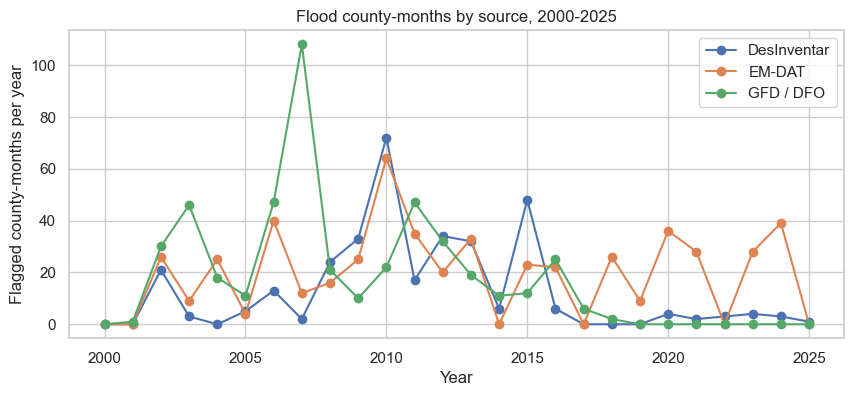

In [24]:
# plot the flagged county-months per year for each source
plt.figure(figsize=(10, 4))
plt.plot(per_year.index, per_year["flood_desinventar"], marker="o", label="DesInventar")
plt.plot(per_year.index, per_year["flood_emdat"], marker="o", label="EM-DAT")
plt.plot(per_year.index, per_year["flood_gfd_dfo"], marker="o", label="GFD / DFO")
plt.xlabel("Year")
plt.ylabel("Flagged county-months per year")
plt.title("Flood county-months by source, 2000-2025")
plt.legend()
plt.show()

**Observation:** Before 2017 the three lines move up and down together in some years (2010-2013) and apart in others (2007). After 2016 GFD/DFO is at 0 and DesInventar is near 0, so only EM-DAT keeps flagging floods. From 2020 to 2024 EM-DAT accounts for 131 of the 144 flagged county-months (91%). This change of label source over time is important for the models: a test period that depends on one source is not the same as the training period.

## 6. The target: a flood next month

The model predicts at the end of month *t* whether month *t+1* has a flood. So `flood_next_month` is `flood_this_month` moved one month back inside each county. The last month (December 2025) has no next month and stays blank. The public version does the same with `flood_this_month_public`.

In [25]:
# sort every county in time order and check that the months are consecutive
labels = labels.sort_values(["pcode", "year", "month"]).reset_index(drop=True)
t = labels["year"] * 12 + labels["month"] - 1
print("every step is exactly 1 month:", (t.groupby(labels["pcode"]).diff().dropna() == 1).all())

every step is exactly 1 month: True


**Observation:** For every county the months are exactly 1 month apart, so shifting by one row is shifting by one month.

In [26]:
# move the label one month back within each county
labels["flood_next_month"] = labels.groupby("pcode")["flood_this_month"].shift(-1)
labels["flood_next_month_public"] = labels.groupby("pcode")["flood_this_month_public"].shift(-1)
print("blank flood_next_month:", labels["flood_next_month"].isna().sum())
print("blank rows are all December 2025:", (labels[labels["flood_next_month"].isna()][["year", "month"]] == [2025, 12]).all().all())
print("flood_next_month = 1:", int(labels["flood_next_month"].sum()), "| public:", int(labels["flood_next_month_public"].sum()))

blank flood_next_month: 47
blank rows are all December 2025: True
flood_next_month = 1: 1069 | public: 749


**Observation:** 47 rows have no next month: December 2025, one per county. `flood_next_month` = 1 in 1,069 rows (749 public), the same as `flood_this_month`, because January 2000 (the only row whose flag is lost in the shift) has no flood.

In [27]:
# worked example: Kisumu in 2007, public labels (each row holds the flag of the following month)
labels[(labels["pcode"] == "KE042") & (labels["year"] == 2007)][["year", "month", "flood_this_month_public", "flood_next_month_public"]]

,year,month,flood_this_month_public,flood_next_month_public
12876,2007,1,0,0.0
12877,2007,2,0,0.0
12878,2007,3,0,0.0
12879,2007,4,0,0.0
12880,2007,5,0,0.0
12881,2007,6,0,1.0
12882,2007,7,1,1.0
12883,2007,8,1,1.0
12884,2007,9,1,1.0
12885,2007,10,1,0.0


**Observation:** In 2007 Kisumu has a public flood flag in July, August, September and October (`flood_this_month_public` = 1). The next-month column is 1 one row earlier: June to September. So at the end of June the model must warn about July, and in October it must predict that the flood is over in November.

### 6.1 heavy_rain_next_month

A simple comparison for the later models: is next month's rain more than 125% of normal (`rain_pct_normal` > 1.25)? It uses next month's rain, which we will not know when we predict, so it is **never a feature**. We keep it only as a yardstick.

In [28]:
# next month's rain_pct_normal and the heavy-rain flag
rain = pd.read_csv("../../data/interim/nb_rain_ndvi_climate.csv", dtype={"pcode": str}, usecols=["pcode", "year", "month", "rain_pct_normal"])
labels = labels.merge(rain, on=["pcode", "year", "month"], how="left", validate="one_to_one")
next_rain = labels.groupby("pcode")["rain_pct_normal"].shift(-1)
labels["heavy_rain_next_month"] = (next_rain > 1.25).astype(float).where(next_rain.notna())
labels = labels.drop(columns="rain_pct_normal")
print("blank:", labels["heavy_rain_next_month"].isna().sum(), "| heavy-rain months:", int(labels["heavy_rain_next_month"].sum()))
print("share of months followed by heavy rain:", labels["heavy_rain_next_month"].mean().round(3))

blank: 47 | heavy-rain months: 3830
share of months followed by heavy rain: 0.262


**Observation:** 26.2% of the months with a known next month (3,830 of 14,617) are followed by rain above 125% of normal, and 47 rows are blank (December 2025). Heavy rain is common, while floods are rare (7.3%), so heavy rain next month alone cannot be a good flood warning.

## 7. county_flood_rate: the flood history of each county

Some counties flood much more often than others (for example around Lake Victoria). The feature `county_flood_rate` gives each county its own history: the share of months with a flood in 2000-2019, pulled a little towards the national share so that a county with few events is not rated 0.

`county_flood_rate = (county_floods + 24 x national_rate) / (240 + 24)`

where `county_floods` is the number of flood months of the county in 2000-2019 (240 months) and `national_rate` is the share of flood months over all counties. The 24 acts like 24 extra months at the national rate. The value is the same on every row of a county.

**Warning for modelling:** it uses all of 2000-2019, so a model that is tested inside this period would see its own answers. In the models it is recomputed inside each training fold.

In [29]:
# worked example: Kisumu, with and without EM-DAT
train = labels[labels["year"].between(2000, 2019)]
national = train["flood_this_month"].mean()
national_public = train["flood_this_month_public"].mean()
kis = train[train["pcode"] == "KE042"]
print("national rate:", round(national, 4), "| public:", round(national_public, 4))
print("Kisumu flood months in 2000-2019:", kis["flood_this_month"].sum(), "of", kis.shape[0], "| public:", kis["flood_this_month_public"].sum())
print("Kisumu rate:", round((kis["flood_this_month"].sum() + 24 * national) / (240 + 24), 4))
print("Kisumu rate public:", round((kis["flood_this_month_public"].sum() + 24 * national_public) / (240 + 24), 4))

national rate: 0.0819 | public: 0.0649
Kisumu flood months in 2000-2019: 49 of 240 | public: 37
Kisumu rate: 0.1931
Kisumu rate public: 0.1461


**Observation:** In 2000-2019 the national flood share is 0.0819 (0.0649 without EM-DAT). Kisumu has 49 flood months of 240 (37 in the public label), so its raw rate is 0.204. The smoothed rate is (49 + 24 x 0.0819) / 264 = 0.1931. The smoothing pulls it a little towards the national rate. Without EM-DAT the rate is 0.1461.

In [30]:
# the rate for every county, full and public
g = train.groupby("pcode")[["flood_this_month", "flood_this_month_public"]].sum()
rate = (g["flood_this_month"] + 24 * national) / (240 + 24)
rate_public = (g["flood_this_month_public"] + 24 * national_public) / (240 + 24)
labels["county_flood_rate"] = labels["pcode"].map(rate)
labels["county_flood_rate_public"] = labels["pcode"].map(rate_public)
print("missing:", labels["county_flood_rate"].isna().sum(), labels["county_flood_rate_public"].isna().sum())
print("county_flood_rate min, median, max:", rate.min().round(4), rate.median().round(4), rate.max().round(4))
print("public min, median, max:", rate_public.min().round(4), rate_public.median().round(4), rate_public.max().round(4))

missing: 0 0
county_flood_rate min, median, max: 0.0112 0.0794 0.1931
public min, median, max: 0.0097 0.0665 0.1461


**Observation:** No county is blank. `county_flood_rate` goes from 0.0112 to 0.1931 with a median of 0.0794 (public: 0.0097 to 0.1461, median 0.0665). The history differs a lot between counties: the highest rate is 17 times the lowest.

In [31]:
# the three counties with the highest and the lowest rate
names = cw.set_index("pcode")["county"]
ranking = pd.DataFrame({"county": names, "flood_months_2000_2019": g["flood_this_month"], "county_flood_rate": rate.round(4)}).sort_values("county_flood_rate")
pd.concat([ranking.head(3), ranking.tail(3)])

,county,flood_months_2000_2019,county_flood_rate
pcode,,,
KE036,Bomet,1,0.0112
KE038,Vihiga,2,0.0150
KE046,Nyamira,2,0.0150
KE004,Tana River,36,0.1438
KE023,Turkana,44,0.1741
KE042,Kisumu,49,0.1931


**Observation:** Kisumu (49 flood months, rate 0.1931), Turkana (44, 0.1741) and Tana River (36, 0.1438) have the highest rates. Bomet (1 month, 0.0112), Vihiga and Nyamira (2 months, 0.0150) have the lowest. Even Bomet, whose raw rate would be 0.004, gets 0.0112 and not 0. Nyamira's low value may partly be because it has no DesInventar column.

## 8. Join everything into the final table

In [32]:
# load the tables of notebooks 01-03
rain_ndvi_climate = pd.read_csv("../../data/interim/nb_rain_ndvi_climate.csv", dtype={"pcode": str})
soil_rivers = pd.read_csv("../../data/interim/nb_soil_rivers.csv", dtype={"pcode": str})
static = pd.read_csv("../../data/interim/nb_static_county.csv", dtype={"pcode": str})
print("grid", grid.shape, "| rain/ndvi/climate", rain_ndvi_climate.shape, "| soil/rivers", soil_rivers.shape, "| static", static.shape, "| labels", labels.shape)

grid (14664, 7) | rain/ndvi/climate (14664, 21) | soil/rivers (14664, 11) | static (47, 21) | labels (14664, 20)


**Observation:** The five tables have the sizes we expect: the grid, the rainfall/NDVI/climate table, the soil/rivers table and the labels each have 14,664 rows, and the static table has 47 rows (one per county).

In [33]:
# left merges onto the grid; the row count must stay 14,664
key = ["pcode", "year", "month"]
final = grid.copy()
final = final.merge(rain_ndvi_climate, on=key, how="left", validate="one_to_one")
print("after rain, ndvi, climate:", len(final))
final = final.merge(soil_rivers, on=key, how="left", validate="one_to_one")
print("after soil, rivers, built-up:", len(final))
final = final.merge(static, on="pcode", how="left", validate="many_to_one")
print("after static columns:", len(final))
final = final.merge(labels, on=key, how="left", validate="one_to_one")
print("after labels:", len(final))

after rain, ndvi, climate: 14664
after soil, rivers, built-up: 14664
after static columns: 14664
after labels: 14664


**Observation:** Each left merge keeps 14,664 rows, so no county-month was lost or duplicated by the joins. The static columns are repeated for each month of a county (a many-to-one merge).

In [34]:
# put the columns in the same order as the pipeline's table and sort the rows
column_order = ["pcode", "county", "year", "month", "season", "month_sin", "month_cos",
    "rain_mm", "rain_max_dekad", "rain_lag1", "rain_lag2", "rain_3mo_total", "rain_pct_normal",
    "neighbour_rain", "neighbour_rain_lag1", "ndvi", "ndvi_pct_normal",
    "oni", "oni_lag1", "oni_lag2", "oni_lag3", "dmi", "dmi_lag1", "dmi_lag2", "dmi_lag3",
    "soil_moisture_l1", "soil_moisture_l1_lag1", "soil_moisture_l2", "soil_moisture_l2_lag1", "runoff_rank",
    "discharge_rank", "discharge_rank_lag1",
    "elevation", "elev_std", "slope", "pct_flat", "area_km2",
    "lc_tree", "lc_shrub", "lc_grass", "lc_crop", "lc_built", "lc_bare", "lc_water", "lc_wetland", "lc_mangrove",
    "pct_within_1km_river", "pct_within_5km_river", "pct_within_1km_water", "pct_water", "pct_occasional_water",
    "pop_density", "pct_built", "county_flood_rate", "county_flood_rate_public",
    "flood_desinventar", "flood_emdat", "flood_gfd", "flood_dfo", "flood_gfd_dfo", "desinventar_no_record_year",
    "n_sources", "flood_this_month", "flood_corroborated",
    "n_sources_public", "flood_this_month_public", "flood_corroborated_public",
    "flood_next_month", "flood_next_month_public", "heavy_rain_next_month"]
print("columns we have but not in the list:", sorted(set(final.columns) - set(column_order)))
print("columns in the list but not in our table:", sorted(set(column_order) - set(final.columns)))
final = final[column_order].sort_values(key).reset_index(drop=True)
print(final.shape, "| duplicate keys:", final.duplicated(key).sum())

columns we have but not in the list: []
columns in the list but not in our table: []
(14664, 70) | duplicate keys: 0


**Observation:** The final table has 14,664 rows and 70 columns. Our columns are exactly the 70 expected ones (nothing extra, nothing missing) and there are no duplicate keys.

In [35]:
# missing values per column (only columns with at least one)
missing = final.isna().sum()
missing[missing > 0]

ndvi                       1410
ndvi_pct_normal            1410
flood_next_month             47
flood_next_month_public      47
heavy_rain_next_month        47
dtype: int64

**Observation:** Only five columns have blanks: `ndvi` and `ndvi_pct_normal` (1,410 each, before July 2002) and the three next-month columns (47 each, December 2025). Everything else is complete.

In [36]:
# save the labels and the final table (both git-ignored: they contain EM-DAT-derived columns)
labels.to_csv("../../data/interim/nb_flood_labels.csv", index=False)
final.to_csv("../../data/interim/nb_model_table_full.csv", index=False)
print("saved nb_flood_labels.csv", labels.shape, "and nb_model_table_full.csv", final.shape)

saved nb_flood_labels.csv (14664, 20) and nb_model_table_full.csv (14664, 70)


**Observation:** We saved the labels (14,664 x 20) and the final table (14,664 x 70) in `data/interim/`, which is git-ignored because they contain EM-DAT-derived columns.

## 9. Final check: is our table the same as the pipeline's table?

The pipeline's full table is `data/private/model_table_full.csv`. We compare it with ours **column by column**: same rows in the same order, and equal values (numbers must agree within 1e-9, with blanks matching blanks). Every column must say PASS.

In [37]:
# load the pipeline's full table and compare the shape, the column names and the keys
pipe = pd.read_csv("../../data/private/model_table_full.csv", dtype={"pcode": str})
print("shape ours / pipeline:", final.shape, pipe.shape)
print("same column names in the same order:", list(final.columns) == list(pipe.columns))
print("same keys in the same order:", (final[key].values == pipe[key].values).all())

shape ours / pipeline: (14664, 70) (14664, 70)
same column names in the same order: True
same keys in the same order: True


**Observation:** Our table and the pipeline's table both have 14,664 rows and 70 columns, with the same column names in the same order and the same keys in the same order.

In [38]:
# column-by-column comparison, one line per column
results = []
for c in pipe.columns:
    if pd.api.types.is_numeric_dtype(pipe[c]):
        same = np.allclose(final[c].astype(float), pipe[c].astype(float), rtol=0, atol=1e-9, equal_nan=True)
    else:
        same = (final[c].astype(str) == pipe[c].astype(str)).all()
    results.append(same)
    print("PASS" if same else "FAIL", c)
print()
print("columns passed:", sum(results), "of", len(results))

PASS pcode
PASS county
PASS year
PASS month
PASS season
PASS month_sin
PASS month_cos
PASS rain_mm
PASS rain_max_dekad
PASS rain_lag1
PASS rain_lag2
PASS rain_3mo_total
PASS rain_pct_normal
PASS neighbour_rain
PASS neighbour_rain_lag1
PASS ndvi
PASS ndvi_pct_normal
PASS oni
PASS oni_lag1
PASS oni_lag2
PASS oni_lag3
PASS dmi
PASS dmi_lag1
PASS dmi_lag2
PASS dmi_lag3
PASS soil_moisture_l1
PASS soil_moisture_l1_lag1
PASS soil_moisture_l2
PASS soil_moisture_l2_lag1
PASS runoff_rank
PASS discharge_rank
PASS discharge_rank_lag1
PASS elevation
PASS elev_std
PASS slope
PASS pct_flat
PASS area_km2
PASS lc_tree
PASS lc_shrub
PASS lc_grass
PASS lc_crop
PASS lc_built
PASS lc_bare
PASS lc_water
PASS lc_wetland
PASS lc_mangrove
PASS pct_within_1km_river
PASS pct_within_5km_river
PASS pct_within_1km_water
PASS pct_water
PASS pct_occasional_water
PASS pop_density
PASS pct_built
PASS county_flood_rate
PASS county_flood_rate_public
PASS flood_desinventar
PASS flood_emdat
PASS flood_gfd
PASS flood_dfo
PA

**Observation:** All 70 columns say PASS and none FAIL (70 of 70). Every value in our table equals the pipeline's value within 1e-9, with blanks in the same places. So the four notebooks of this folder rebuild the model table exactly.

## Summary

- **Labels:** DesInventar and GFD were rebuilt from their raw files and match the ready-made file. DFO and EM-DAT flags are read from the pipeline because they need hand-checked place lookups (EM-DAT stays private).
- **Rules:** GFD and DFO count as one source; `n_sources` counts DesInventar, EM-DAT and GFD/DFO; `flood_this_month` needs 1 source and `flood_corroborated` 2.
- **Target:** `flood_next_month` is the label moved one month back inside each county (December 2025 stays blank). `heavy_rain_next_month` is only a yardstick, never a feature.
- **County history:** `county_flood_rate` is a smoothed flood share for 2000-2019 and is recomputed inside each training fold in the models.
- **Final table:** 14,664 rows x 70 columns, with every column equal to the pipeline's `model_table_full.csv`. Saved to `data/interim/nb_model_table_full.csv` (git-ignored).
- The EDA notebooks in `notebooks/2_eda/` use the pipeline table `data/private/model_table_full.csv`, which is identical to ours.